## 01. Load the features

In [1]:
import numpy as np
from pathlib import Path

FEATURE_DIR = Path("../features/").resolve()

with np.load(FEATURE_DIR / "combined_weighted_features.npz") as data:
    X_train = data["X_train"]
    X_val = data["X_val"]

    y_train = data["y_train"]
    y_val = data["y_val"]

    train_paths = data["train_paths"]
    val_paths = data["val_paths"]

    classes = data["classes"]
    feature_groups = data["feature_groups"]
    feature_dimensions = data["feature_dimensions"]
    feature_weights = data["feature_weights"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)
print("Classes:", classes)

for name, dim, weight in zip(
    feature_groups, feature_dimensions, feature_weights
):
    print(f"{name}: {dim} features, weight={weight}")

Training features: (2160, 8206)
Validation features: (541, 8206)
Training labels: (2160,)
Validation labels: (541,)
Classes: ['Fire' 'Smoke' 'Neutral']
rgb: 48 features, weight=1.0
hsv: 48 features, weight=1.0
lbp: 10 features, weight=1.0
hog: 8100 features, weight=1.0


In [2]:
feature_names = ["rgb", "hsv", "lbp", "hog"]

features = {}

for name in feature_names:
    filepath = FEATURE_DIR / f"{name}_features.npz"

    with np.load(filepath) as data:
        features[name] = {
            "X_train": data["X_train"],
            "X_val": data["X_val"],
            "y_train": data["y_train"],
            "y_val": data["y_val"],
        }

    print(
        name.upper(),
        "Train:", features[name]["X_train"].shape,
        "Val:", features[name]["X_val"].shape
    )


X_train_rgb = features["rgb"]["X_train"]
X_train_hsv = features["hsv"]["X_train"]
X_train_lbp = features["lbp"]["X_train"]
X_train_hog = features["hog"]["X_train"]


X_val_rgb = features['rgb']['X_val']
X_val_hsv = features['hsv']['X_val']
X_val_lbp = features['lbp']['X_val']
X_val_hog = features['hog']['X_val']

RGB Train: (2160, 48) Val: (541, 48)
HSV Train: (2160, 48) Val: (541, 48)
LBP Train: (2160, 10) Val: (541, 10)
HOG Train: (2160, 8100) Val: (541, 8100)


## 02. Import path and directories

In [14]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler, Normalizer,normalize
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,precision_score,recall_score
)

from IPython.display import display
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


In [4]:
MODEL_DIR =  Path("../models/svm_models").resolve()
MODEL_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
print("Feature folder:", FEATURE_DIR)
print("Model folder:  ", MODEL_DIR)

Feature folder: /Users/sreeramc/Desktop/UC_Berkeley/281/Project_repo/MIDS-281-project/features
Model folder:   /Users/sreeramc/Desktop/UC_Berkeley/281/Project_repo/MIDS-281-project/models/svm_models


## 03. Prediction Individual models

### RGB Alone

RGB Validation Accuracy: 0.6654343807763401
              precision    recall  f1-score   support

        Fire       0.79      0.68      0.73       180
       Smoke       0.63      0.69      0.66       180
     Neutral       0.59      0.62      0.61       181

    accuracy                           0.67       541
   macro avg       0.67      0.67      0.67       541
weighted avg       0.67      0.67      0.67       541



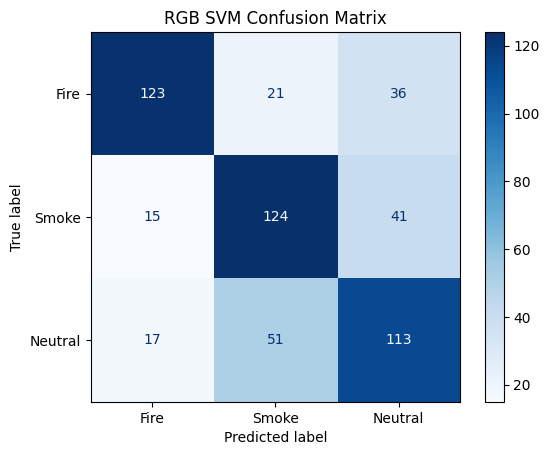

In [6]:
rgb_svm_model = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    )

rgb_svm_model.fit(X_train_rgb,y_train)

y_pred_rgb = rgb_svm_model.predict(X_val_rgb)

print(
    "RGB Validation Accuracy:",
    accuracy_score(y_val, y_pred_rgb)
)

print(
    classification_report(
        y_val,
        y_pred_rgb,
        target_names=classes
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_rgb,
    display_labels=classes,
    cmap="Blues"
)

plt.title("RGB SVM Confusion Matrix")
plt.show()

### HSV alone

HSV Validation Accuracy: 0.6765249537892791
              precision    recall  f1-score   support

        Fire       0.80      0.69      0.74       180
       Smoke       0.66      0.73      0.69       180
     Neutral       0.59      0.61      0.60       181

    accuracy                           0.68       541
   macro avg       0.68      0.68      0.68       541
weighted avg       0.68      0.68      0.68       541



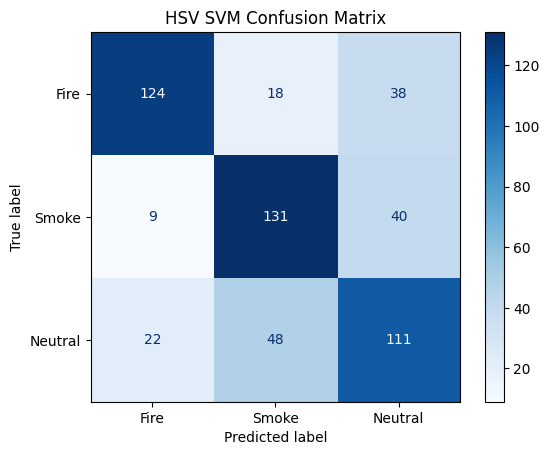

In [7]:
hsv_svm_model = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    )

hsv_svm_model.fit(X_train_hsv,y_train)

y_pred_hsv = hsv_svm_model.predict(X_val_hsv)

print(
    "HSV Validation Accuracy:",
    accuracy_score(y_val, y_pred_hsv)
)

print(
    classification_report(
        y_val,
        y_pred_hsv,
        target_names=classes
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_hsv,
    display_labels=classes,
    cmap="Blues"
)

plt.title("HSV SVM Confusion Matrix")
plt.show()

### HOG Alone

HOG Validation Accuracy: 0.6765249537892791
              precision    recall  f1-score   support

        Fire       0.65      0.70      0.67       180
       Smoke       0.60      0.52      0.56       180
     Neutral       0.77      0.81      0.79       181

    accuracy                           0.68       541
   macro avg       0.67      0.68      0.67       541
weighted avg       0.67      0.68      0.67       541



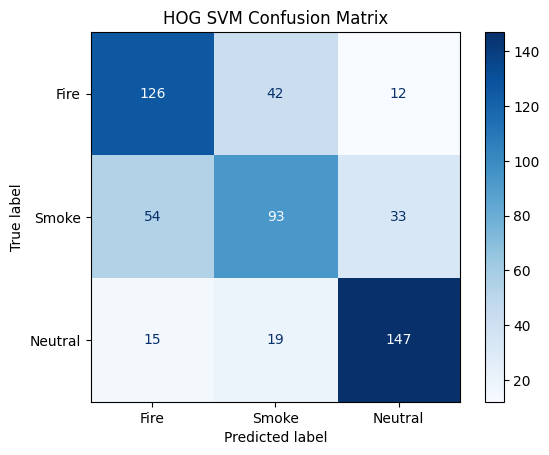

In [8]:
hog_svm_model = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    )

hog_svm_model.fit(X_train_hog,y_train)

y_pred_hog = hog_svm_model.predict(X_val_hog)

print(
    "HOG Validation Accuracy:",
    accuracy_score(y_val, y_pred_hog)
)

print(
    classification_report(
        y_val,
        y_pred_hog,
        target_names=classes
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_hog,
    display_labels=classes,
    cmap="Blues"
)

plt.title("HOG SVM Confusion Matrix")
plt.show()

### LBP alone

LBP Validation Accuracy: 0.6487985212569316
              precision    recall  f1-score   support

        Fire       0.58      0.67      0.62       180
       Smoke       0.62      0.44      0.51       180
     Neutral       0.74      0.83      0.79       181

    accuracy                           0.65       541
   macro avg       0.65      0.65      0.64       541
weighted avg       0.65      0.65      0.64       541



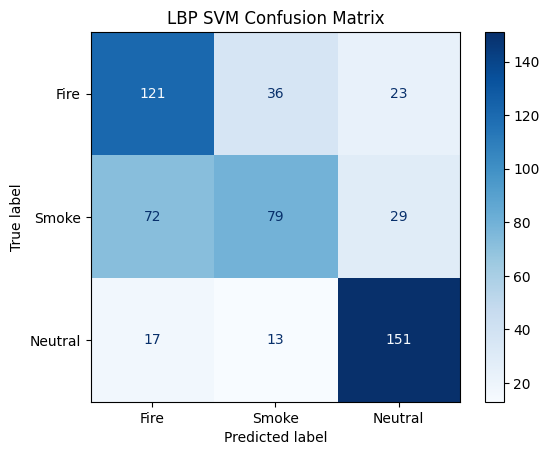

In [9]:
lbp_svm_model = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    )

lbp_svm_model.fit(X_train_lbp,y_train)

y_pred_lbp = lbp_svm_model.predict(X_val_lbp)

print(
    "LBP Validation Accuracy:",
    accuracy_score(y_val, y_pred_lbp)
)

print(
    classification_report(
        y_val,
        y_pred_lbp,
        target_names=classes
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_lbp,
    display_labels=classes,
    cmap="Blues"
)

plt.title("LBP SVM Confusion Matrix")
plt.show()

## 04. Prediction Models Combined

Combined Validation Accuracy: 0.8262476894639557
              precision    recall  f1-score   support

        Fire       0.88      0.76      0.82       180
       Smoke       0.77      0.84      0.81       180
     Neutral       0.84      0.88      0.86       181

    accuracy                           0.83       541
   macro avg       0.83      0.83      0.83       541
weighted avg       0.83      0.83      0.83       541



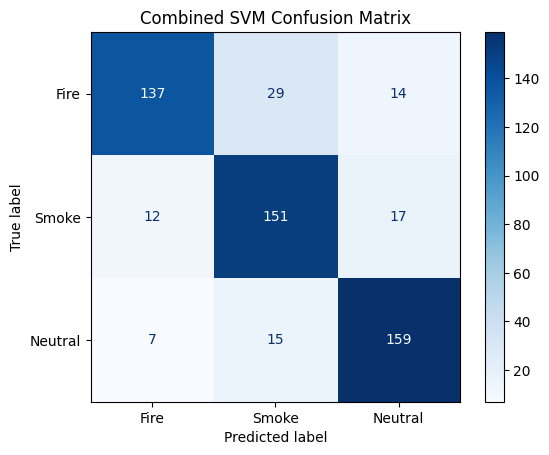

In [10]:
combined_svm_model = SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    )

combined_svm_model.fit(X_train,y_train)

y_pred_combined = combined_svm_model.predict(X_val)

print(
    "Combined Validation Accuracy:",
    accuracy_score(y_val, y_pred_combined)
)

print(
    classification_report(
        y_val,
        y_pred_combined,
        target_names=classes
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_val,
    y_pred_combined,
    display_labels=classes,
    cmap="Blues"
)

plt.title("Combined SVM Confusion Matrix")
plt.show()

## 05. Results

In [15]:

predictions = {
    "RGB": y_pred_rgb,
    "HSV": y_pred_hsv,
    "LBP": y_pred_lbp,
    "HOG": y_pred_hog,
    "Combined": y_pred_combined
}

feature_counts = {
    "RGB": X_train_rgb.shape[1],
    "HSV": X_train_hsv.shape[1],
    "LBP": X_train_lbp.shape[1],
    "HOG": X_train_hog.shape[1],
    "Combined": X_train.shape[1]
}

results = []

for model, y_pred in predictions.items():
    results.append({
        "Model": model,
        "Features": feature_counts[model],
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(
            y_val, y_pred, average="macro"
        ),
        "Recall": recall_score(
            y_val, y_pred, average="macro"
        ),
        "F1 Score": f1_score(
            y_val, y_pred, average="macro"
        )
    })

comparison_df = (
    pd.DataFrame(results)
    .sort_values("Accuracy", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.round(4))

# comparison_df.to_csv(
#     "svm_comparison.csv", index=False
# )


,Model,Features,Accuracy,Precision,Recall,F1 Score
0,Combined,8206,0.8262,0.8298,0.8262,0.8260
1,HSV,48,0.6765,0.6841,0.6766,0.6784
2,HOG,8100,0.6765,0.6719,0.6763,0.6724
3,RGB,48,0.6654,0.6736,0.6655,0.6677
4,LBP,10,0.6488,0.6457,0.6485,0.6400


## 06. Hyperparameter tuning